# 통계값과 분포 정답지

분석 목적 → 데이터 이해 → 요약 → 해석 순서로 진행합니다. CRISP-DM에서는 업무 이해와 데이터 이해가 먼저입니다. 통계는 불확실성을 설명하고, 마이닝은 패턴을 찾고, ML/DL은 예측·표현 학습에 활용합니다. 큰 데이터도 표본 편향을 없애 주지는 않습니다.

**학습 목표:** 기술통계와 추론통계, 평균·중앙값·최빈값, 편차·분산·표준편차, 사분위수·IQR·이상치 후보, 같은 평균, 다른 분포

공식 → 직접 구현 또는 계산 → 라이브러리 대조 → 해석 순서로 학습합니다.

## 실행 준비

Python 3.11 이상, NumPy·pandas·SciPy·Matplotlib이 필요합니다. 없는 경우 별도 셀에서 `%pip install numpy pandas scipy matplotlib`을 한 번 실행하세요. 새 커널에서 위에서 아래로 실행합니다. 외부 데이터 다운로드는 없습니다. 그래프는 폰트 호환을 위해 영문 제목을 쓰고 해석은 한국어로 제공합니다.

**표기:** 기본 기술 분산은 ddof=0, 모집단 분산 추정·평균 추론은 ddof=1을 명시합니다. 난수는 seed=42(문제에 지정 시 해당 seed)입니다.

In [1]:
import math
from collections import Counter
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
# 외부 파일 없이 재현 가능한 학습용 가상 자료
x = np.array([12, 15, 14, 10, 18, 20, 22, 25, 30, 28], dtype=float)
y = np.array([2, 4, 6, 8, 10, 12, 14, 40], dtype=float)
plt.rcParams['axes.unicode_minus'] = False


## 문제 1. 기술통계와 추론통계

고객 등급 [Bronze, Gold, Bronze, Silver, Gold, Gold]의 빈도·비율을 구하고, 등급이 서열척도인 이유와 전체 고객으로 일반화할 때 필요한 조건을 쓰세요.

**점검 기준:** 요구한 계산값·그래프와 사용한 가정, 단위를 함께 기록하세요.

In [2]:
# 문제 1 풀이
s = pd.Series(['Bronze','Gold','Bronze','Silver','Gold','Gold'])
print(pd.DataFrame({'빈도':s.value_counts(), '비율':s.value_counts(normalize=True)}))

        빈도        비율
Gold     3  0.500000
Bronze   2  0.333333
Silver   1  0.166667


**결과 해석 / 근거 / 새로 알게 된 점:**

등급에는 순서가 있지만 등급 사이 간격은 일정한 숫자가 아닙니다. 편의 표본 6명만으로 전체 고객 비율을 확정할 수 없습니다.

## 문제 2. 평균·중앙값·최빈값

y의 평균·중앙값·최빈값을 구하세요. 40을 400으로 바꾸면 어떤 대표값이 크게 바뀌나요?

**점검 기준:** 요구한 계산값·그래프와 사용한 가정, 단위를 함께 기록하세요.

In [3]:
# 문제 2 풀이
print(y.mean(), np.median(y), pd.Series(y).mode().tolist())
y2=y.copy(); y2[-1]=400
print(y2.mean(), np.median(y2))
assert np.isclose(y.mean(),12)

12.0 9.0 [2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 40.0]
57.0 9.0


**결과 해석 / 근거 / 새로 알게 된 점:**

평균 12, 중앙값 9입니다. 모든 값이 1번이므로 모든 값이 공동 최빈값입니다. 400으로 바꾸면 평균은 57, 중앙값은 9로 유지됩니다.

## 문제 3. 편차·분산·표준편차

자료 [2,4,6]에 대해 평균, 편차, 편차제곱, 모분산, 표본분산과 각각의 표준편차를 계산하세요.

**점검 기준:** 요구한 계산값·그래프와 사용한 가정, 단위를 함께 기록하세요.

In [4]:
# 문제 3 풀이
a=np.array([2.,4.,6.]); dev=a-a.mean()
print('평균',a.mean(),'편차',dev,'제곱',dev**2)
for d in (0,1): print('ddof',d,'분산',a.var(ddof=d),'표준편차',a.std(ddof=d))
assert np.isclose(a.var(),8/3) and np.isclose(a.var(ddof=1),4)

평균 4.0 편차 [-2.  0.  2.] 제곱 [4. 0. 4.]
ddof 0 분산 2.6666666666666665 표준편차 1.632993161855452
ddof 1 분산 4.0 표준편차 2.0


**결과 해석 / 근거 / 새로 알게 된 점:**

평균 4, 편차 [-2,0,2], 제곱 [4,0,4]입니다. 모분산 8/3, 표본분산 4이므로 표준편차도 달라집니다. 자료를 전체로 기술하는지 모집단을 추정하는지 먼저 정합니다.

## 문제 4. 사분위수·IQR·이상치 후보

y의 Q1,Q3,IQR, 양쪽 경계와 이상치 후보를 구하세요. 경계와 정확히 같은 값은 후보인가요?

**점검 기준:** 요구한 계산값·그래프와 사용한 가정, 단위를 함께 기록하세요.

In [5]:
# 문제 4 풀이
q1,q3=np.quantile(y,[.25,.75],method='linear'); iqr=q3-q1
lo,hi=q1-1.5*iqr,q3+1.5*iqr
print(q1,q3,iqr,lo,hi,y[(y<lo)|(y>hi)])
assert np.allclose([q1,q3,iqr,lo,hi],[5.5,12.5,7,-5,23])

5.5 12.5 7.0 -5.0 23.0 [40.]


**결과 해석 / 근거 / 새로 알게 된 점:**

Q1=5.5, Q3=12.5, IQR=7, 경계 −5와 23, 후보는 40입니다. 엄격한 부등호 기준이므로 경계와 같은 값은 포함하지 않습니다.

## 문제 5. 같은 평균, 다른 분포

y의 bins=4 히스토그램과 박스플롯을 나란히 그리고 평균만으로 요약할 때 놓치는 정보를 적으세요.

**점검 기준:** 요구한 계산값·그래프와 사용한 가정, 단위를 함께 기록하세요.

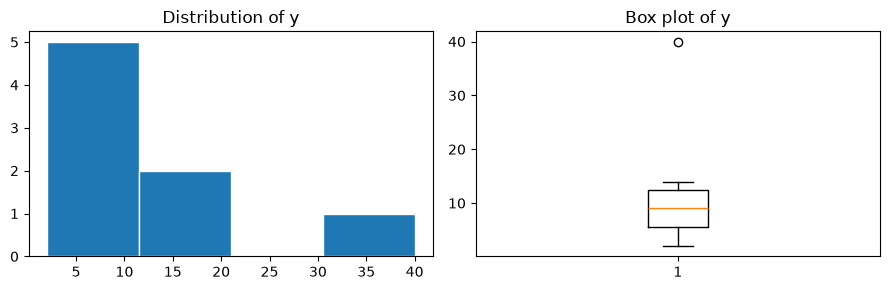

평균 12.0 중앙값 9.0 왜도 2.222222222222222


In [6]:
# 문제 5 풀이
fig,axes=plt.subplots(1,2,figsize=(9,3))
axes[0].hist(y,bins=4,edgecolor='white');axes[0].set_title('Distribution of y')
axes[1].boxplot(y);axes[1].set_title('Box plot of y')
plt.tight_layout();plt.show()
print('평균',y.mean(),'중앙값',np.median(y),'왜도',stats.skew(y,bias=False))

**결과 해석 / 근거 / 새로 알게 된 점:**

오른쪽의 큰 값 40과 긴 꼬리, 중앙 50%의 퍼짐은 평균 하나로 알 수 없습니다. bins를 바꾸어도 결론이 안정적인지 확인합니다.

## 복습 순서

1. 관측 대상과 통계량의 의미를 말로 설명합니다.
2. 분모·단위·독립성·분포 가정을 확인합니다.
3. 직접 계산과 라이브러리 결과를 비교합니다.
4. 코드 결과와 실제로 주장할 수 있는 범위를 구분합니다.

**학습 이동:** `Statistics_1_descriptive.ipynb` → `Statistics_1_descriptive_Practice.ipynb` → `Statistics_1_descriptive_Answer.ipynb`.